<a href="https://colab.research.google.com/github/h8naf1/FSD_Tugas-Kelompok-Linear-Regression-dan-Logistic-Regression-/blob/main/A_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAGIAN A: LINEAR REGRESSION — PREDIKSI HARGA RUMAH DI YOGYAKARTA

## A1. Deskripsi Dataset
- **Sumber Dataset**: Kaggle (Dataset Harga Rumah Yogyakarta oleh Jasa Aplikasi Skripsi)
- **Tautan Dataset**: https://www.kaggle.com/datasets/jasaaplikasiskripsi/dataset-harga-rumah-yogyakarta
- **Format Awal**: JSON
- **Variabel Target**: `price` (Harga Rumah/Sewa dalam Rupiah — Numerik Kontinu)
- **Fitur Prediktor**:
  1. `Luas_bangunan`: Luas bangunan dalam meter persegi (m²)
  2. `Luas_tanah`: Luas tanah dalam meter persegi (m²)
  3. `Kamar_tidur`: Jumlah kamar tidur
  4. `Kamar_Mandi`: Jumlah kamar mandi

In [8]:
import json
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Memuat dataset JSON
with open('dataset-harga-rumah-yogyakarta.json', 'r', encoding='utf-8') as f:
    data_json = json.load(f)

# 2. Extrak data JSON ke bentuk list of dictionaries
rows = []
for item in data_json:
    params = item.get('parameters', {})
    row = {
        'title': item.get('title', ''),
        'price_raw': item.get('price', ''),
        'Luas_bangunan': params.get('Luas_bangunan', None),
        'Luas_tanah': params.get('Luas_tanah', None),
        'Kamar_tidur': params.get('Kamar_tidur', None),
        'Kamar_Mandi': params.get('Kamar_Mandi', None),
        'Lantai': params.get('Lantai', None),
        'Alamat_lokasi': params.get('Alamat_lokasi', '')
    }
    rows.append(row)

df = pd.DataFrame(rows)
print(f"Jumlah baris awal: {df.shape[0]}, Jumlah kolom awal: {df.shape[1]}")
df.head()

Jumlah baris awal: 562, Jumlah kolom awal: 8


,title,price_raw,Luas_bangunan,Luas_tanah,Kamar_tidur,Kamar_Mandi,Lantai,Alamat_lokasi
0,Disewakan family homestay di Yogyakarta - Dise...,Rp 1.000.000,250,300,4,3,1,"Jl sonosewu 120, seberang Superindo minimarket"
1,Perumahan Baru Dalam Ring Road Maguwo Bukan Hy...,Rp 2.375.000.000,126,125,3,3,0,
2,Cluster Mewah 2 Lantai Arkadia Townhouse Maguw...,Rp 2.145.000.000,150,120,4,3,2,
3,dijual tanah bonus rumah pinggir jalan raya ho...,Rp 960.000.000,140,160,3,2,0,
4,Rumah Siap Huni 4 Kamar Halaman Luas - Dijual:...,Rp 1.650.000.000,135,168,4,2,2,Wedomartani


## A2. Preprocessing Data (Pembersihan & Transformasi Teks ke Numerik)
Data mentah memiliki format string (teks) pada kolom harga dan spesifikasi rumah.
Langkah pembersihan yang dilakukan:
1. Ekstraksi angka dari kolom `price_raw` (menghapus "Rp" dan titik) menjadi numerik `price`.
2. Mengubah fitur `Luas_bangunan`, `Luas_tanah`, `Kamar_tidur`, dan `Kamar_Mandi` menjadi tipe data numerik (float/int).
3. Mengatasi missing values (nilai kosong) dan menghapus duplikat.
4. Menghapus outlier pada harga dan luas rumah agar model tidak bias.

In [9]:
# Fungsi pembersihan harga
def clean_price(val):
    if pd.isna(val): return np.nan
    val_clean = re.sub(r'[^0-9]', '', str(val))
    return float(val_clean) if val_clean else np.nan

# Fungsi pembersihan fitur numerik
def clean_num(val):
    if pd.isna(val): return np.nan
    val_clean = re.sub(r'[^0-9.]', '', str(val))
    try:
        return float(val_clean)
    except:
        return np.nan

# Penerapan pembersihan
df['price'] = df['price_raw'].apply(clean_price)
df['Luas_bangunan'] = df['Luas_bangunan'].apply(clean_num)
df['Luas_tanah'] = df['Luas_tanah'].apply(clean_num)
df['Kamar_tidur'] = df['Kamar_tidur'].apply(clean_num)
df['Kamar_Mandi'] = df['Kamar_Mandi'].apply(clean_num)

# Pilih kolom yang relevan
cols_needed = ['Luas_bangunan', 'Luas_tanah', 'Kamar_tidur', 'Kamar_Mandi', 'price']
df_clean = df[cols_needed].copy()

# Hapus missing values dan duplikat
df_clean = df_clean.dropna().drop_duplicates()

# Hapus outlier sederhana menggunakan IQR pada harga
Q1 = df_clean['price'].quantile(0.25)
Q3 = df_clean['price'].quantile(0.75)
IQR = Q3 - Q1
df_clean = df_clean[(df_clean['price'] >= (Q1 - 1.5 * IQR)) & (df_clean['price'] <= (Q3 + 1.5 * IQR))]

print(f"Jumlah baris setelah pembersihan: {df_clean.shape[0]}")
df_clean.describe()

Jumlah baris setelah pembersihan: 437


,Luas_bangunan,Luas_tanah,Kamar_tidur,Kamar_Mandi,price
count,437.000000,437.000000,437.000000,437.000000,4.370000e+02
mean,163.029748,241.529748,3.645309,2.606407,1.315128e+09
std,327.908050,1439.650965,2.095223,2.042160,1.149093e+09
min,10.000000,0.000000,1.000000,1.000000,3.000000e+05
25%,65.000000,91.000000,2.000000,1.000000,4.350001e+08
50%,115.000000,124.000000,3.000000,2.000000,9.900000e+08
75%,190.000000,175.000000,4.000000,3.000000,1.900000e+09
max,4676.000000,30000.000000,10.000000,10.000000,4.800000e+09


## A3. Eksplorasi dan Visualisasi Data (EDA)
Di bawah ini dilakukan visualisasi untuk memahami karakteristik data:
1. **Histogram Distribusi Harga**: Untuk melihat sebaran variabel target.
2. **Heatmap Korelasi**: Untuk melihat tingkat hubungan antar-fitur numerik dan variabel target.
3. **Scatter Plot (Luas Bangunan vs Harga)**: Untuk melihat hubungan linier antara luas bangunan dan harga properti.

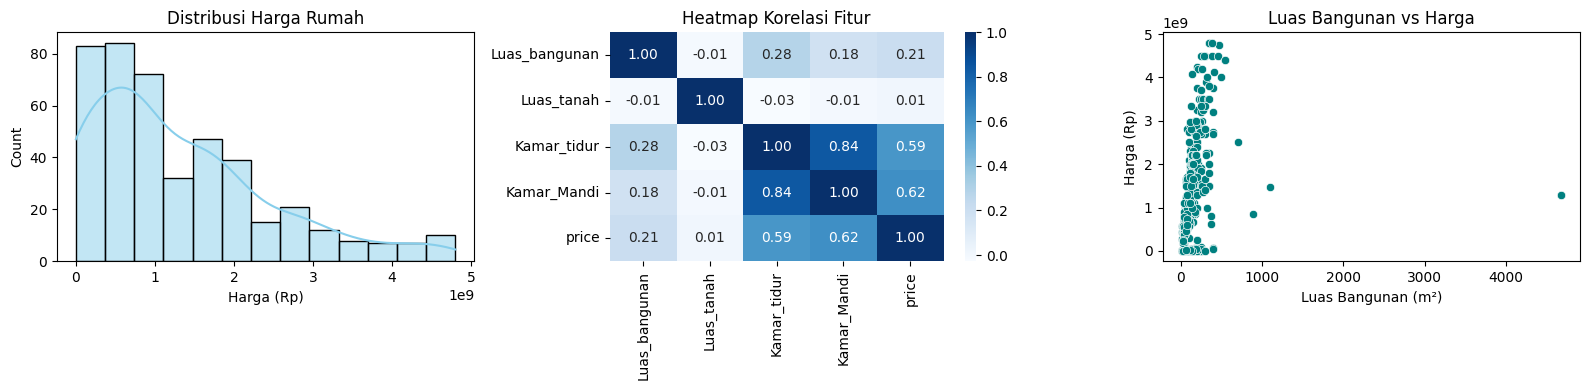

In [10]:
plt.figure(figsize=(16, 4))

# 1. Histogram Distribusi Harga
plt.subplot(1, 3, 1)
sns.histplot(df_clean['price'], kde=True, color='skyblue')
plt.title('Distribusi Harga Rumah')
plt.xlabel('Harga (Rp)')

# 2. Heatmap Korelasi
plt.subplot(1, 3, 2)
sns.heatmap(df_clean.corr(), annot=True, cmap='Blues', fmt=".2f")
plt.title('Heatmap Korelasi Fitur')

# 3. Scatter Plot Luas Bangunan vs Harga
plt.subplot(1, 3, 3)
sns.scatterplot(data=df_clean, x='Luas_bangunan', y='price', color='teal')
plt.title('Luas Bangunan vs Harga')
plt.xlabel('Luas Bangunan (m²)')
plt.ylabel('Harga (Rp)')

plt.tight_layout()
plt.show()

### Temuan EDA:
1. Distribusi harga cenderung *skewed* ke kanan (sebagian besar properti berada di rentang harga menengah ke bawah).
2. Terdapat korelasi positif yang cukup kuat antara `Luas_bangunan` dan `Luas_tanah` terhadap `price`.
3. Fitur `Luas_bangunan` menunjukkan pola hubungan linier yang paling jelas terhadap harga.

## A4. Pemilihan Fitur & A5. Pembagian Data
- Fitur yang digunakan sebagai prediktor ($X$): `Luas_bangunan`, `Luas_tanah`, `Kamar_tidur`, dan `Kamar_Mandi`.
- Variabel target ($y$): `price`.
- Data dibagi menjadi **80% Data Latih (Train)** dan **20% Data Uji (Test)** dengan `random_state=42`.

In [11]:
X = df_clean[['Luas_bangunan', 'Luas_tanah', 'Kamar_tidur', 'Kamar_Mandi']]
y = df_clean['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Ukuran Data Latih: {X_train.shape[0]} baris")
print(f"Ukuran Data Uji  : {X_test.shape[0]} baris")

Ukuran Data Latih: 349 baris
Ukuran Data Uji  : 88 baris


## A6. Pemodelan Linear Regression
Model dibentuk menggunakan algoritma `LinearRegression` dari library Scikit-Learn.

In [12]:
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# Menampilkan Koefisien dan Intercept
print(f"Intercept (a): {model_lr.intercept_:,.2f}")
print("\nKoefisien Fitur (b):")
for feature, coef in zip(X.columns, model_lr.coef_):
    print(f"- {feature}: {coef:,.2f}")

Intercept (a): 93,040,946.12

Koefisien Fitur (b):
- Luas_bangunan: 198,708.29
- Luas_tanah: 886,425.44
- Kamar_tidur: 143,846,819.48
- Kamar_Mandi: 201,992,686.09


## A7. Evaluasi Model
Metrik evaluasi yang digunakan: MAE (Mean Absolute Error), MSE (Mean Squared Error), RMSE (Root Mean Squared Error), dan R-squared ($R^2$).

--- METRIK EVALUASI (DATA UJI) ---
MAE  : Rp 876,842,176.97
MSE  : 8,563,642,327,789,814,784.00
RMSE : Rp 2,926,370,162.47
R2 (Train) : 0.4435
R2 (Test)  : -8.2904


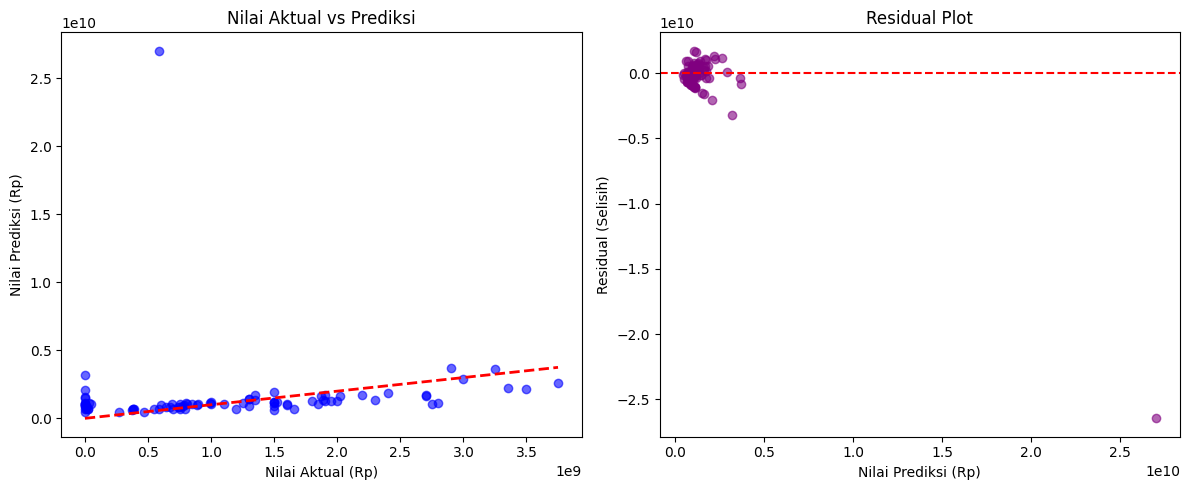

In [13]:
# Prediksi
y_train_pred = model_lr.predict(X_train)
y_test_pred = model_lr.predict(X_test)

# Evaluasi Data Latih
r2_train = r2_score(y_train, y_train_pred)

# Evaluasi Data Uji
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2_test = r2_score(y_test, y_test_pred)

print("--- METRIK EVALUASI (DATA UJI) ---")
print(f"MAE  : Rp {mae:,.2f}")
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : Rp {rmse:,.2f}")
print(f"R2 (Train) : {r2_train:.4f}")
print(f"R2 (Test)  : {r2_test:.4f}")

# Visualisasi Aktual vs Prediksi & Residual Plot
residuals = y_test - y_test_pred

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_test_pred, alpha=0.6, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Nilai Aktual vs Prediksi')
plt.xlabel('Nilai Aktual (Rp)')
plt.ylabel('Nilai Prediksi (Rp)')

plt.subplot(1, 2, 2)
plt.scatter(y_test_pred, residuals, alpha=0.6, color='purple')
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residual Plot')
plt.xlabel('Nilai Prediksi (Rp)')
plt.ylabel('Residual (Selisih)')

plt.tight_layout()
plt.show()

### A8. Analisis Performa Model

1. **Performa Model:** Nilai \(R^2\) pada data latih sebesar 0,4435 menunjukkan bahwa model mampu menjelaskan sekitar 44,35% variasi harga rumah pada data latih. Namun, nilai \(R^2\) pada data uji sebesar -8,2904 menunjukkan bahwa performa model dalam memprediksi data baru masih sangat buruk.

2. **Overfitting dan Generalisasi:** Terdapat perbedaan yang besar antara nilai \(R^2\) data latih dan data uji. Hal ini menunjukkan bahwa model belum mampu melakukan generalisasi dengan baik. Nilai \(R^2\) data uji yang negatif berarti prediksi model lebih buruk dibandingkan jika menggunakan rata-rata harga rumah dari data latih sebagai prediksi.

3. **Pengaruh Fitur:** Model menggunakan luas bangunan, luas tanah, jumlah kamar tidur, dan jumlah kamar mandi untuk memprediksi harga rumah. Koefisien regresi menunjukkan hubungan estimasi setiap fitur dengan harga ketika fitur lainnya dianggap tetap. Namun, besarnya koefisien tidak cukup untuk memastikan bahwa luas bangunan merupakan fitur yang paling berpengaruh tanpa evaluasi tambahan.

4. **Keterbatasan Model:** Model Linear Regression hanya menangkap hubungan linear antara fitur dan harga rumah. Performa yang kurang baik pada data uji dapat berkaitan dengan pencilan harga, perbedaan karakteristik properti, atau faktor penting yang belum dimasukkan, seperti lokasi dan kondisi bangunan. Oleh karena itu, model masih perlu dievaluasi dan dikembangkan sebelum digunakan untuk memperkirakan harga rumah secara praktis.